# Supervised Classification on the Iris Dataset
Logistic Regression vs. Decision Tree with feature scaling, an 80/20 split, and benchmark metrics (accuracy, precision, recall, F1-score).

**Workflow:** load data → exploratory pairplot → scale features → train models → evaluate → confusion matrices → decision boundaries → comparison.

## 1. Imports and configuration

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import ListedColormap

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)

RANDOM_STATE = 42
sns.set_theme(style="whitegrid", context="notebook")

## 2. Load the dataset

In [2]:
df = pd.read_csv("iris.csv")
print(f"Shape: {df.shape}")
df.head()

Shape: (150, 5)


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   sepal_length  150 non-null    float64
 1   sepal_width   150 non-null    float64
 2   petal_length  150 non-null    float64
 3   petal_width   150 non-null    float64
 4   species       150 non-null    str    
dtypes: float64(4), str(1)
memory usage: 6.0 KB


In [4]:
print("Missing values per column:")
print(df.isnull().sum())
print(f"\nDuplicate rows: {df.duplicated().sum()}")
print("\nClass distribution:")
print(df["species"].value_counts())

Missing values per column:
sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
species         0
dtype: int64

Duplicate rows: 1

Class distribution:
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
sepal_length,150.0,5.843333,0.828066,4.3,5.1,5.80,6.4,7.9
sepal_width,150.0,3.057333,0.435866,2.0,2.8,3.00,3.3,4.4
petal_length,150.0,3.758000,1.765298,1.0,1.6,4.35,5.1,6.9
petal_width,150.0,1.199333,0.762238,0.1,0.3,1.30,1.8,2.5


## 3. Exploratory data analysis

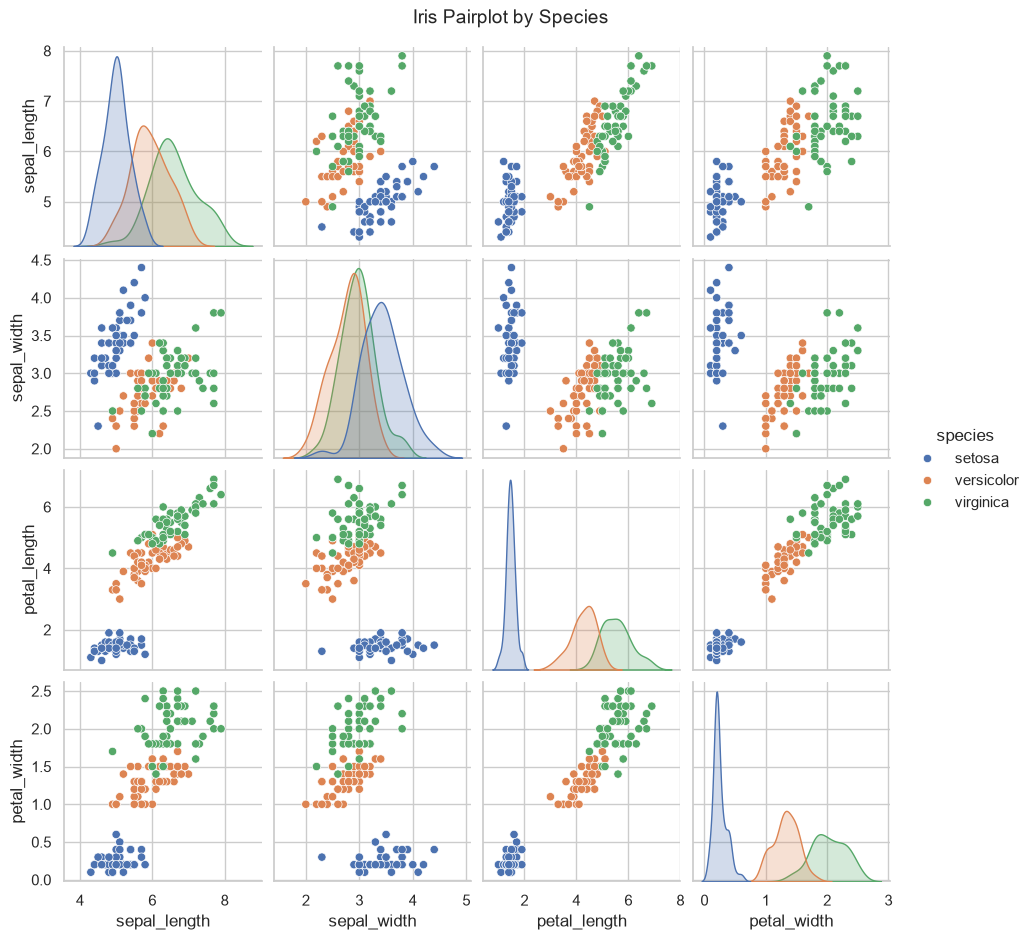

In [6]:
palette = {"setosa": "#4C72B0", "versicolor": "#DD8452", "virginica": "#55A868"}
g = sns.pairplot(df, hue="species", palette=palette, diag_kind="kde", height=2.3, corner=False)
g.figure.suptitle("Iris Pairplot by Species", y=1.02, fontsize=14)
plt.show()

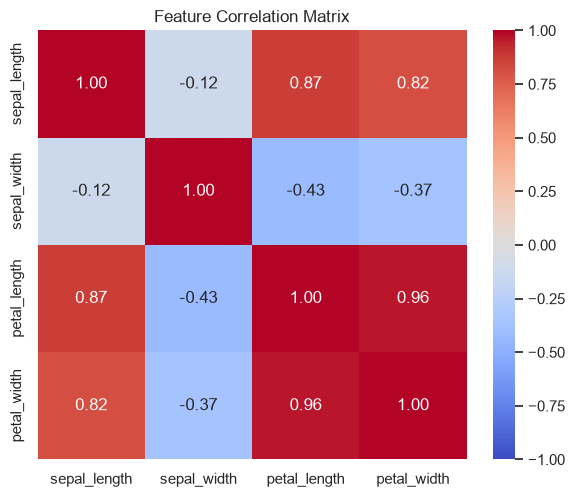

In [7]:
fig, ax = plt.subplots(figsize=(6, 5))
corr = df.drop(columns="species").corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True, ax=ax)
ax.set_title("Feature Correlation Matrix")
plt.tight_layout()
plt.show()

**Observations.** Setosa is linearly separable from the other two species on the petal measurements. Versicolor and virginica overlap slightly, so that pair is where most classification errors are expected. Petal length and petal width are strongly correlated (about 0.96) and are the most discriminative features.

## 4. Feature preparation, 80/20 split and scaling

In [8]:
feature_cols = ["sepal_length", "sepal_width", "petal_length", "petal_width"]
X = df[feature_cols]

encoder = LabelEncoder()
y = encoder.fit_transform(df["species"])
class_names = encoder.classes_

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

print(f"Train: {X_train.shape[0]} samples | Test: {X_test.shape[0]} samples")
print("Train class counts:", np.bincount(y_train))
print("Test class counts: ", np.bincount(y_test))

Train: 120 samples | Test: 30 samples
Train class counts: [40 40 40]
Test class counts:  [10 10 10]


In [9]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

pd.DataFrame(X_train_scaled, columns=feature_cols).describe().loc[["mean", "std"]].round(3)

,sepal_length,sepal_width,petal_length,petal_width
mean,-0.000,0.000,0.000,0.000
std,1.004,1.004,1.004,1.004


The scaler is fitted on the training set only and then applied to the test set, which prevents information from the test data leaking into training.

## 5. Model training

In [10]:
log_reg = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
log_reg.fit(X_train_scaled, y_train)

tree = DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE)
tree.fit(X_train_scaled, y_train)

models = {"Logistic Regression": log_reg, "Decision Tree": tree}
predictions = {name: model.predict(X_test_scaled) for name, model in models.items()}

## 6. Evaluation

In [11]:
for name, y_pred in predictions.items():
    print("=" * 60)
    print(name)
    print("=" * 60)
    print(classification_report(y_test, y_pred, target_names=class_names, digits=3))

Logistic Regression
              precision    recall  f1-score   support

      setosa      1.000     1.000     1.000        10
  versicolor      0.900     0.900     0.900        10
   virginica      0.900     0.900     0.900        10

    accuracy                          0.933        30
   macro avg      0.933     0.933     0.933        30
weighted avg      0.933     0.933     0.933        30

Decision Tree
              precision    recall  f1-score   support

      setosa      1.000     1.000     1.000        10
  versicolor      1.000     0.900     0.947        10
   virginica      0.909     1.000     0.952        10

    accuracy                          0.967        30
   macro avg      0.970     0.967     0.967        30
weighted avg      0.970     0.967     0.967        30



In [12]:
rows = []
for name, y_pred in predictions.items():
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision (macro)": precision_score(y_test, y_pred, average="macro"),
        "Recall (macro)": recall_score(y_test, y_pred, average="macro"),
        "F1-score (macro)": f1_score(y_test, y_pred, average="macro"),
        "Precision (weighted)": precision_score(y_test, y_pred, average="weighted"),
        "Recall (weighted)": recall_score(y_test, y_pred, average="weighted"),
        "F1-score (weighted)": f1_score(y_test, y_pred, average="weighted"),
    })

results = pd.DataFrame(rows).set_index("Model").round(4)
results

,Accuracy,Precision (macro),Recall (macro),F1-score (macro),Precision (weighted),Recall (weighted),F1-score (weighted)
Model,,,,,,,
Logistic Regression,0.9333,0.9333,0.9333,0.9333,0.9333,0.9333,0.9333
Decision Tree,0.9667,0.9697,0.9667,0.9666,0.9697,0.9667,0.9666


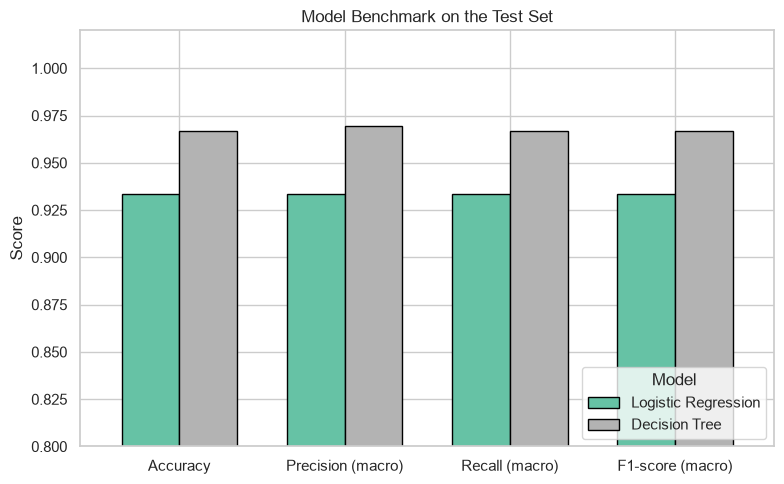

In [13]:
ax = results[["Accuracy", "Precision (macro)", "Recall (macro)", "F1-score (macro)"]].T.plot(
    kind="bar", figsize=(8, 5), colormap="Set2", edgecolor="black", width=0.7
)
ax.set_ylim(0.8, 1.02)
ax.set_ylabel("Score")
ax.set_title("Model Benchmark on the Test Set")
ax.legend(title="Model", loc="lower right")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 7. Confusion matrix heatmaps

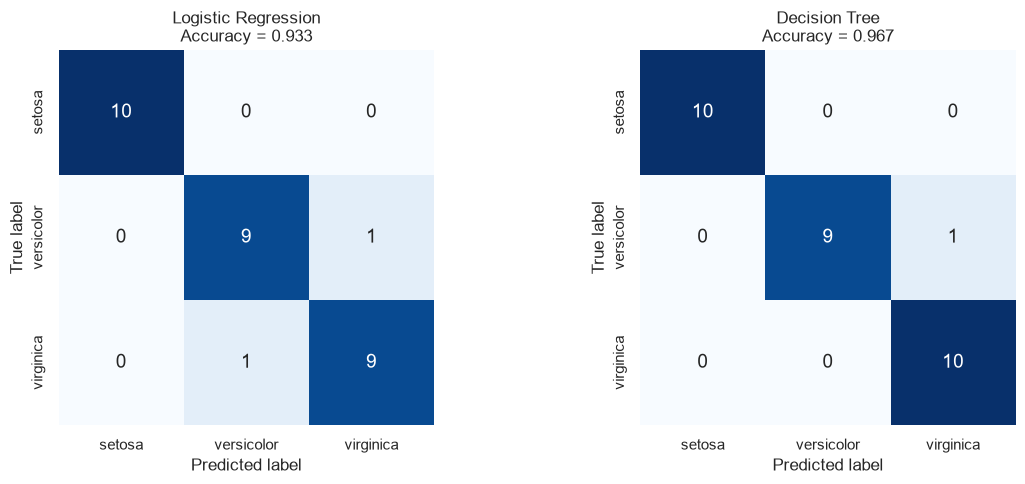

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, (name, y_pred) in zip(axes, predictions.items()):
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, square=True,
                xticklabels=class_names, yticklabels=class_names,
                annot_kws={"size": 14}, ax=ax)
    ax.set_title(f"{name}\nAccuracy = {accuracy_score(y_test, y_pred):.3f}")
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("True label")

plt.tight_layout()
plt.show()

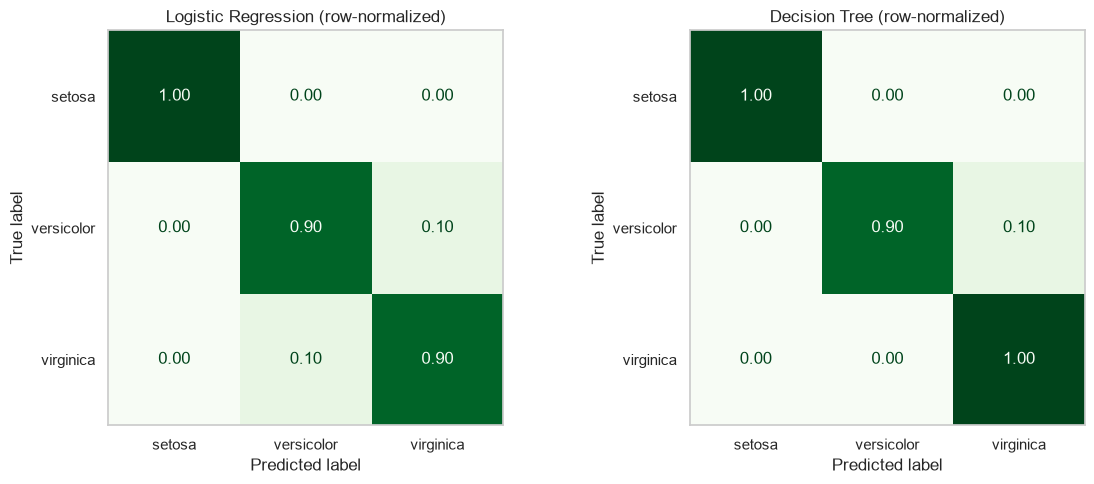

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, (name, y_pred) in zip(axes, predictions.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_test, y_pred, display_labels=class_names, normalize="true",
        cmap="Greens", values_format=".2f", colorbar=False, ax=ax
    )
    ax.set_title(f"{name} (row-normalized)")
    ax.grid(False)

plt.tight_layout()
plt.show()

## 8. Decision boundary visualization
Decision boundaries can only be drawn in two dimensions, so separate models are fitted on the two most discriminative features (petal length and petal width), using the same split and scaling procedure. These 2-D models are for visualization only; the benchmark above uses all four features.

In [16]:
viz_cols = ["petal_length", "petal_width"]

Xv_train, Xv_test, yv_train, yv_test = train_test_split(
    df[viz_cols], y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

viz_scaler = StandardScaler()
Xv_train_s = viz_scaler.fit_transform(Xv_train)
Xv_test_s = viz_scaler.transform(Xv_test)

viz_models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    "Decision Tree": DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE),
}
for model in viz_models.values():
    model.fit(Xv_train_s, yv_train)

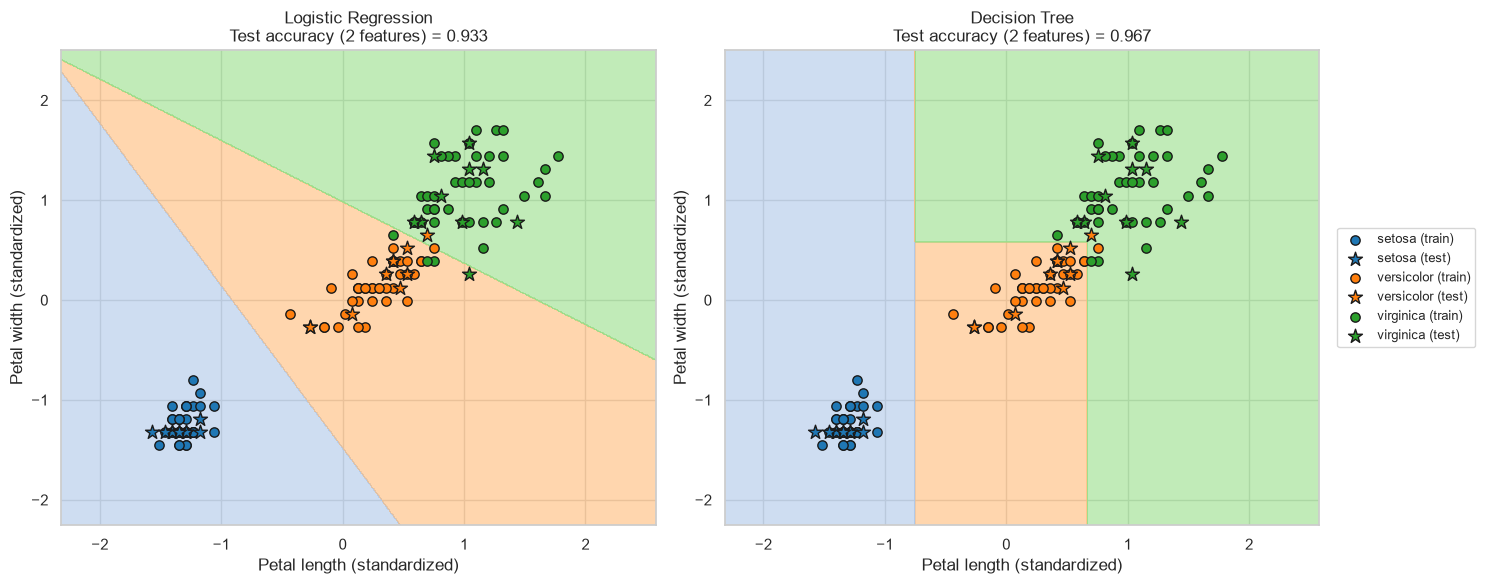

In [17]:
def plot_decision_boundary(model, X_tr, y_tr, X_te, y_te, title, ax):
    x_min, x_max = X_tr[:, 0].min() - 0.8, X_tr[:, 0].max() + 0.8
    y_min, y_max = X_tr[:, 1].min() - 0.8, X_tr[:, 1].max() + 0.8
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 500), np.linspace(y_min, y_max, 500))
    zz = model.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

    light = ListedColormap(["#AEC7E8", "#FFBB78", "#98DF8A"])
    bold = ["#1F77B4", "#FF7F0E", "#2CA02C"]

    ax.contourf(xx, yy, zz, cmap=light, alpha=0.6)
    for idx, label in enumerate(class_names):
        ax.scatter(X_tr[y_tr == idx, 0], X_tr[y_tr == idx, 1], c=bold[idx],
                   edgecolor="k", s=45, label=f"{label} (train)")
        ax.scatter(X_te[y_te == idx, 0], X_te[y_te == idx, 1], c=bold[idx],
                   edgecolor="k", s=110, marker="*", label=f"{label} (test)")

    acc = accuracy_score(y_te, model.predict(X_te))
    ax.set_title(f"{title}\nTest accuracy (2 features) = {acc:.3f}")
    ax.set_xlabel("Petal length (standardized)")
    ax.set_ylabel("Petal width (standardized)")
    ax.set_xlim(x_min, x_max)
    ax.set_ylim(y_min, y_max)


fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, (name, model) in zip(axes, viz_models.items()):
    plot_decision_boundary(model, Xv_train_s, yv_train, Xv_test_s, yv_test, name, ax)
axes[1].legend(loc="center left", bbox_to_anchor=(1.02, 0.5), fontsize=9)
plt.tight_layout()
plt.show()

The logistic regression boundaries are straight lines, while the decision tree produces axis-aligned rectangular regions. Both separate setosa cleanly and place the versicolor/virginica boundary in roughly the same area.

## 9. Model interpretation

In [18]:
coef_df = pd.DataFrame(log_reg.coef_.T, index=feature_cols, columns=class_names).round(3)
coef_df

,setosa,versicolor,virginica
sepal_length,-1.089,0.536,0.553
sepal_width,1.024,-0.360,-0.664
petal_length,-1.799,-0.204,2.003
petal_width,-1.686,-0.808,2.494


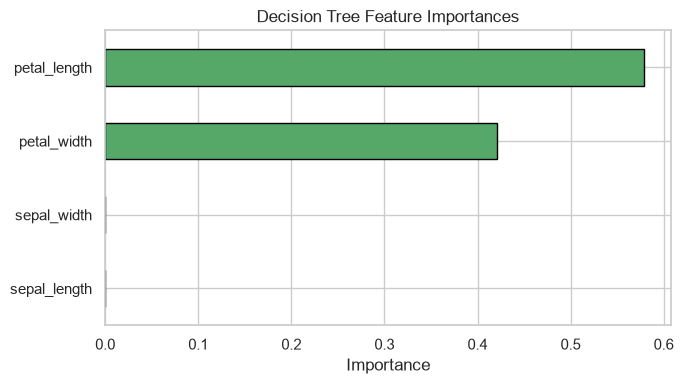

In [19]:
importances = pd.Series(tree.feature_importances_, index=feature_cols).sort_values()
ax = importances.plot(kind="barh", figsize=(7, 4), color="#55A868", edgecolor="black")
ax.set_xlabel("Importance")
ax.set_title("Decision Tree Feature Importances")
plt.tight_layout()
plt.show()

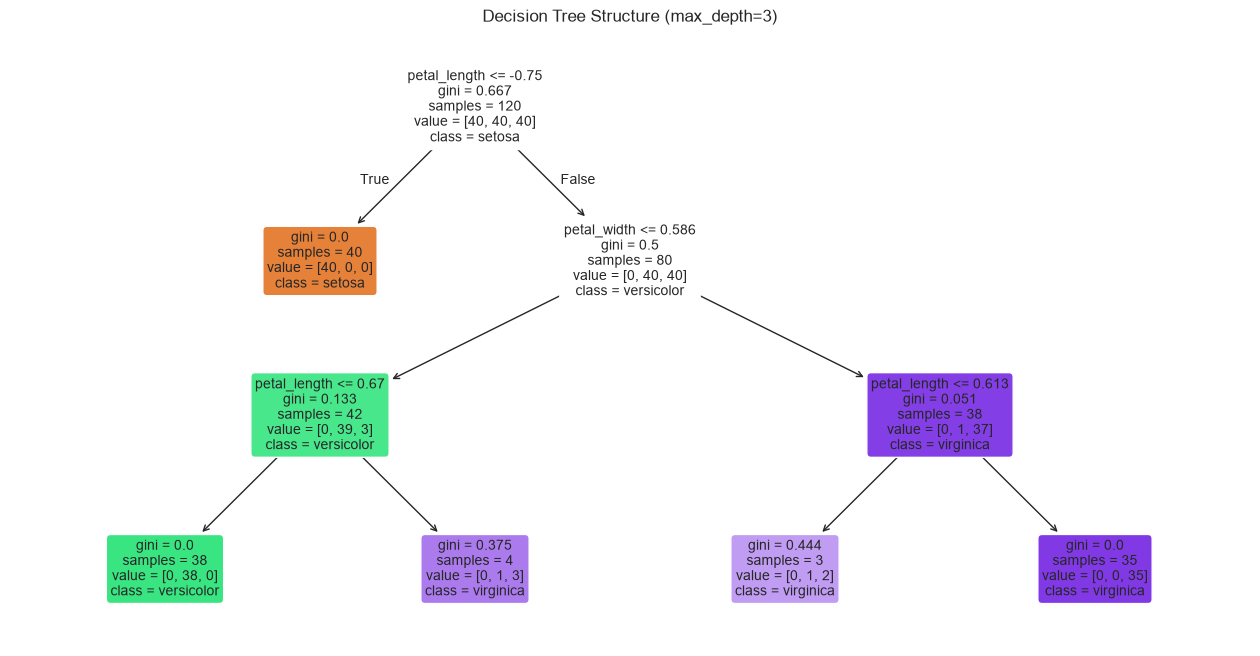

In [20]:
from sklearn.tree import plot_tree

plt.figure(figsize=(16, 8))
plot_tree(tree, feature_names=feature_cols, class_names=list(class_names),
          filled=True, rounded=True, fontsize=10)
plt.title("Decision Tree Structure (max_depth=3)")
plt.show()

## 10. Cross-validation check
A single 80/20 split on 150 samples gives a noisy estimate, so stratified 5-fold cross-validation is used to confirm the ranking of the two models.

In [21]:
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = ["accuracy", "precision_macro", "recall_macro", "f1_macro"]

cv_rows = {}
for name, estimator in {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    "Decision Tree": DecisionTreeClassifier(max_depth=3, random_state=RANDOM_STATE),
}.items():
    pipe = make_pipeline(StandardScaler(), estimator)
    scores = cross_validate(pipe, X, y, cv=cv, scoring=scoring)
    cv_rows[name] = {m: f"{scores[f'test_{m}'].mean():.3f} ± {scores[f'test_{m}'].std():.3f}" for m in scoring}

pd.DataFrame(cv_rows).T

,accuracy,precision_macro,recall_macro,f1_macro
Logistic Regression,0.953 ± 0.045,0.955 ± 0.044,0.953 ± 0.045,0.953 ± 0.045
Decision Tree,0.960 ± 0.025,0.963 ± 0.023,0.960 ± 0.025,0.960 ± 0.025


## 11. Conclusion

In [22]:
best = results["Accuracy"].idxmax()
print(f"Best test accuracy: {best} ({results.loc[best, 'Accuracy']:.4f})\n")
results[["Accuracy", "Precision (macro)", "Recall (macro)", "F1-score (macro)"]]

Best test accuracy: Decision Tree (0.9667)



,Accuracy,Precision (macro),Recall (macro),F1-score (macro)
Model,,,,
Logistic Regression,0.9333,0.9333,0.9333,0.9333
Decision Tree,0.9667,0.9697,0.9667,0.9666


- Both models perform strongly on Iris because the classes are well separated, with setosa perfectly classified and nearly all errors involving versicolor and virginica.
- Logistic Regression and the depth-limited Decision Tree reach similar scores. The 5-fold cross-validation gives a more reliable comparison than the single hold-out test set of 30 samples.
- Petal length and petal width carry almost all of the predictive signal, which matches the pairplot and the tree's feature importances.
- Scaling matters mainly for Logistic Regression (regularized, gradient-based optimization); the Decision Tree is invariant to it.
- Limiting tree depth to 3 keeps the model interpretable and reduces overfitting on such a small dataset.